# Задания 1 и 2

## Датасет

In [13]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("dataset.csv")
print(df.columns)

Index(['model', 'launchDate', 'numCores', 'numThreads', 'baseClock',
       'maxboostClock', 'allCoreBoostSpeed', 'L1Cache', 'L2Cache', 'L3Cache',
       'processTech', 'PCIeVersion', 'PCIeLanes', 'defaultTDP', 'configTDP',
       'tjMax', 'sysMemType', 'sysMemSpecs', 'memChannels', 'perSocketMemBW',
       'graphicsCores', 'graphicsFreq', 'unlocked', 'platform', 'cpuSocket',
       'socketCount', 'family', 'line', 'graphicsModel', 'thermalSolution'],
      dtype='str')


In [14]:
df

,model,launchDate,numCores,numThreads,baseClock,maxboostClock,allCoreBoostSpeed,L1Cache,L2Cache,L3Cache,...,graphicsCores,graphicsFreq,unlocked,platform,cpuSocket,socketCount,family,line,graphicsModel,thermalSolution
0,AMD Ryzen™ 5 6600H,2022.0,6.0,12.0,3.3,4.5,NaN,384.0,3.0,16.0,...,6.0,1900.0,No,Laptop,FP7,NaN,AMD Ryzen™ Processors,AMD Ryzen™ 5 Mobile Processors with Radeon™ Gr...,AMD Radeon™ 660M,NaN
1,AMD Ryzen™ 5 6600HS​,2022.0,6.0,12.0,3.3,4.5,NaN,384.0,3.0,16.0,...,6.0,1900.0,No,Laptop,FP7,NaN,AMD Ryzen™ Processors,AMD Ryzen™ 5 Mobile Processors with Radeon™ Gr...,AMD Radeon™ 660M,NaN
2,AMD Ryzen™ 5 6600U,2022.0,6.0,12.0,2.9,4.5,NaN,384.0,3.0,16.0,...,6.0,1900.0,No,Laptop,FP7,NaN,AMD Ryzen™ Processors,AMD Ryzen™ 5 Mobile Processors with Radeon™ Gr...,AMD Radeon™ 660M,NaN
3,AMD Ryzen™ 5 PRO 6650H,2022.0,6.0,12.0,3.3,4.5,NaN,384.0,3.0,16.0,...,6.0,1900.0,No,Laptop,NaN,NaN,AMD Ryzen™ PRO Processors,AMD Ryzen™ 5 PRO 6000 Series Mobile Processors,AMD Radeon™ 660M,NaN
4,AMD Ryzen™ 5 PRO 6650HS,2022.0,6.0,12.0,3.3,4.5,NaN,384.0,3.0,16.0,...,6.0,1900.0,No,Laptop,NaN,NaN,AMD Ryzen™ PRO Processors,AMD Ryzen™ 5 PRO 6000 Series Mobile Processors,AMD Radeon™ 660M,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
577,TL-56,NaN,NaN,NaN,1.8,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,No,Laptop,S1,NaN,AMD Turion™,AMD Turion™ 64 X2 Dual-Core Mobile Technology,NaN,NaN
578,TL-60,NaN,2.0,2.0,2.0,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,No,Laptop,S1,NaN,AMD Turion™,AMD Turion™ 64 X2 Dual-Core Mobile Technology,NaN,NaN
579,TL-64,NaN,2.0,2.0,2.2,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,No,Laptop,S1,NaN,AMD Turion™,AMD Turion™ 64 X2 Dual-Core Mobile Technology,NaN,NaN
580,X1150,NaN,4.0,4.0,2.0,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,No,Server,FT3,NaN,AMD Opteron™,AMD Opteron™ X1100 Series Processors,NaN,NaN


## utils

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

POSITIVE_CLASS = 1

def calculate_metrics(model, name, plots=True):
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, POSITIVE_CLASS] if hasattr(model, 'predict_proba') else model.decision_function(X_test)

    if plots:
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax[0])
        RocCurveDisplay.from_predictions(y_test, score, ax=ax[1])
        ax[0].set_title(f'Confusion matrix ({name})')
        ax[1].set_title(f'ROC ({name})')
        plt.tight_layout()
        plt.show()
        print(classification_report(y_test, pred))

    return pd.Series({
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, score),
    }, name=name)

## Задание 1
---

### Выбор целевого признака

В качестве целевого признака будем использовать признак `unlocked`, поскольку он является бинарным и не таким очевидным и тривиальным, как, например, наличие встроенной графики (хотя тоже уместно)

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)


SEED = 4323245
TARGET = 'unlocked'
TEST_SIZE = 0.2

df = df.dropna(subset=[TARGET])


X = df.drop(columns=[TARGET])
y = df[TARGET].map({'Yes': 1, 'No': 0}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y #стратификация по таргету
)

display(y.value_counts(normalize=True).to_frame(name="Баланс классов"))


,Баланс классов
unlocked,
0,0.707566
1,0.292434


In [17]:
train_stats = pd.DataFrame({
    'missing_ratio': X_train.isna().mean() * 100,
    'num_unique': X_train.nunique()
}).sort_values(by='missing_ratio', ascending=False)
display(train_stats)

,missing_ratio,num_unique
allCoreBoostSpeed,100.000000,0
perSocketMemBW,100.000000,0
socketCount,96.163683,1
PCIeLanes,91.304348,2
thermalSolution,90.025575,6
configTDP,79.283887,10
launchDate,55.498721,7
graphicsCores,54.219949,11
PCIeVersion,50.895141,2
graphicsFreq,45.268542,39


### Отбор признаков

Убираем часть признаков по следующим причинам:
- `line` - много уникальных значений, частичная утечка данных
- `model`, `graphicsModel` - много уникальных значений
- `allCoreBoostSpeed`, `perSocketMemBW`, `socketCount`, `PCIeLanes`, `thermalSolution`, `configTDP` - много пропусков

Проверим корреляцию Спирмена между оставшимися числовыми признаками

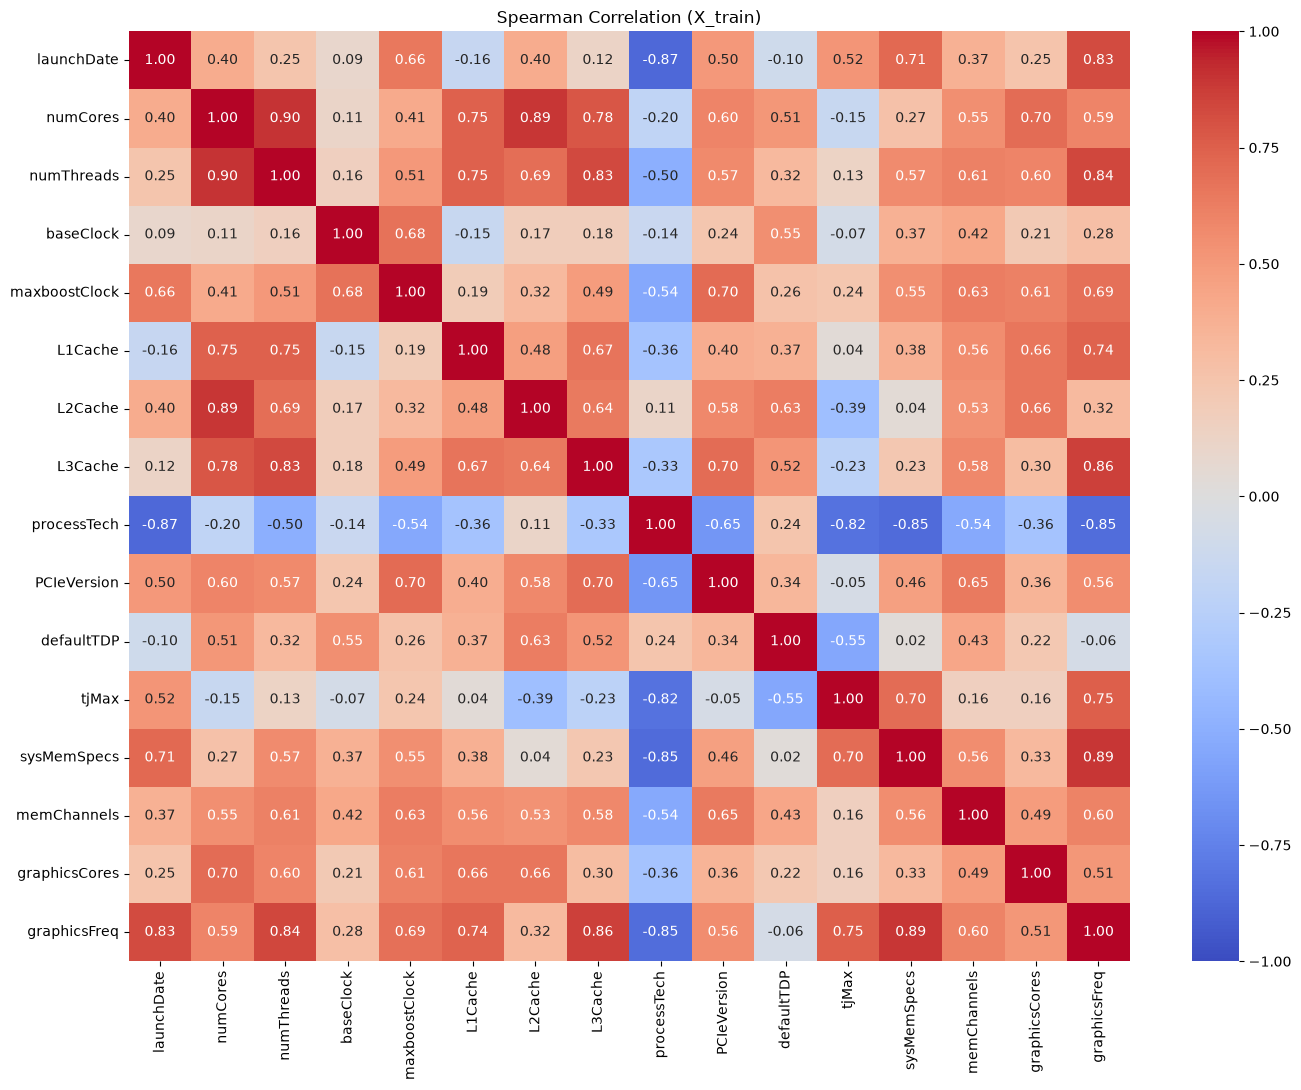

In [18]:
temp_drop_cols = ['line', 'model', 'graphicsModel', 'allCoreBoostSpeed', 'perSocketMemBW', 'socketCount', 'PCIeLanes', 'thermalSolution', 'configTDP']  

cur_cols = [c for c in X_train.columns if c not in temp_drop_cols]
spearman_corr = X_train[cur_cols].select_dtypes('number').corr(method='spearman')


plt.figure(figsize=(14, 11))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman Correlation (X_train)')
plt.tight_layout()

Хоть для классификации допустимы признаки с мультиколлинеарностью, по матрице можно подтвердить часть структурных дублей, а именно `numCores` и `numThreads`, а также `launchDate` и `processTech`


Удаление `numThreads` обоснованно, тк он является производным от `numCores`, а связь `launchDate` и `processTech` по сути является отражением эпохи, и вдобавок `launchDate` содержит много пропусков, поэтому стоит отказаться от первого

Остальные признаки удалять сомнительно, так как они могут быть полезны для классификации, несмотря на корреляцию

In [19]:
DROP_COLS = [
    'model', 'line', 'allCoreBoostSpeed', 'perSocketMemBW', 
    'socketCount', 'PCIeLanes', 'thermalSolution', 'configTDP', 
    'numThreads', 'launchDate', 'graphicsModel'
]

FEATURE_COLS = [col for col in X_train.columns if col not in DROP_COLS]

CAT_COLS = X_train[FEATURE_COLS].select_dtypes(exclude='number').columns.tolist()

NUM_COLS = [col for col in FEATURE_COLS if col not in CAT_COLS]

X_train = X_train[FEATURE_COLS].copy()
X_test = X_test[FEATURE_COLS].copy()


### Пайплайн


In [20]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

#для группировки редких категорий, чтобы псевдопризнаки не разрастались
ENCODER_MIN_FREQ = 5 

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        min_frequency=ENCODER_MIN_FREQ,
        handle_unknown='ignore',
        sparse_output=False)
    )
])

transformer = ColumnTransformer([
    ('num', num_pipeline, NUM_COLS),
    ('cat', cat_pipeline, CAT_COLS)
])

# X_train_pr = transformer.fit_transform(X_train)
# X_test_pr = transformer.transform(X_test)

transformer


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### Обучение логистической регрессии


Для логистической регрессии были заданы следующие параметры:

`C` задает обратную силу регуляризации. Малое значение сильно сжимает веса и вызывает риск недообучения, большое почти не штрафует и может привести риск переобучения, поэтому оптимальное значение подбирается кросс-валидацией по логарифмической сетке, тк эффект от C мультипликативный и важен порядок величины, а не конкретное значение

Scroing-метрикой выбрана F1, тк она учитывает precision и recall вместе, а поодиночке они малоинформативны из-за дисбаланса классов, перебор по 5-кратной стратифицированной кросс-валидации

`class_weight` ($s_i$) для задания весов ошибок класса. balanced делает его обратно пропорциональным частоте класса, те ошибки на редком классе штрафуются сильнее. Сравниваем с отсутствием весов, поскольку классы несбалансированы.
В качестве регуляризации используем L2, так как она более устойчива к мультиколлинеарности признаков, чем L1

`max_iter` делаем 1000 для запаса, тк значение по-умолчанию может не сойтись

В качестве солвера используется стандартный `lbfgs`, который поддерживает только L2 регуляризацию, что также оптимально, тк L2 корректно сжимает мультиколлинеарные признаки


минимизируем $\frac{1}{2}\|w\|^2 + C \sum_i s_i \cdot  -(y_i \ln a_i + (1 - y_i)\ln(1 - a_i))$

Подобранные гиперпараметры:


,classifier__C,classifier__class_weight
Value,100.0,None


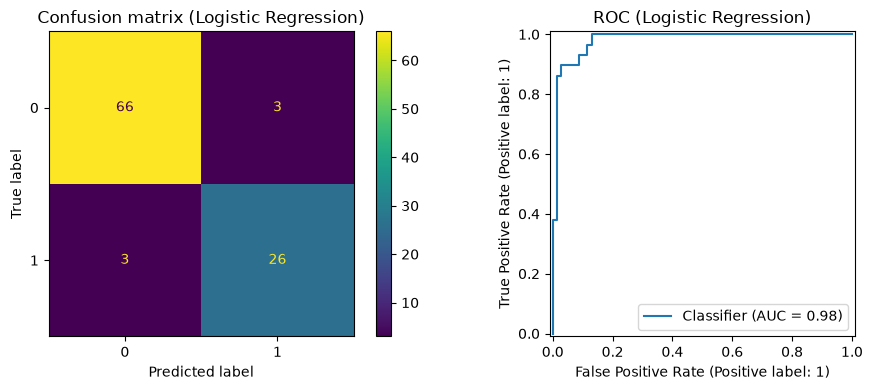

              precision    recall  f1-score   support

           0       0.96      0.96      0.96        69
           1       0.90      0.90      0.90        29

    accuracy                           0.94        98
   macro avg       0.93      0.93      0.93        98
weighted avg       0.94      0.94      0.94        98



Accuracy     0.938776
Precision    0.896552
Recall       0.896552
F1           0.896552
ROC-AUC      0.980510
Name: Logistic Regression, dtype: float64

In [ ]:

#отдельный пайплайн, чтобы не было утечек данных в кроссвалидации из-за трансформера
lr = Pipeline([
    ('transformer', transformer),
    ('classifier', LogisticRegression(
        l1_ratio=0, #l2 регуляризация
        solver='lbfgs',
        max_iter=1000
    ))
])

lr_grid = GridSearchCV(
    lr,
    param_grid={
        'classifier__C': np.logspace(-3, 2, 6),
        # сравнение None и balanced
        'classifier__class_weight': [None, 'balanced']
    },
    scoring='f1',
    cv=5
)

lr_grid.fit(X_train, y_train)

lr_best = lr_grid.best_estimator_

print("Подобранные гиперпараметры:")
display(pd.DataFrame(lr_grid.best_params_, index=['Value']))

calculate_metrics(lr_best, 'Logistic Regression')

### Вывод

Логистическая регрессия показывает хорошее разделение классов на стандартизированных признаках. ROC-AUC близок к единице, те классы хорошо ранжируются линейной моделью на выбранных признаках. Ошибки распределены поровну между ложными срабатываниями и пропусками, перекоса в одну сторону нет. Сдвиг recall и precision можно объяснить небольшим числом положительных объектов в выборке по сравнению с отрицательными

## Задание 2
---
### Бинарная классификация с помощью SVM

`C` в SVM представляет собой штраф за нарушение отступа. Большое C даёт узкую полосу и мало нарушений => риск переобучения, малое C даёт широкую полосу и больше нарушений => риск недообучения. Значение подбирается так же, как для лог регрессии по логарифмической сетке с F1 и 5-кратная стратифицированной кросс-валидацией.
В качестве ядра выбрано `kernel='linear'`

минимизируем $\frac{1}{2}\|w\|^2 + C \sum_i s_i \cdot \max\big(0,\; 1 - y_i (w \cdot x_i + b)\big)$

Подобранные гиперпараметры:


,classifier__C
Value,1.0


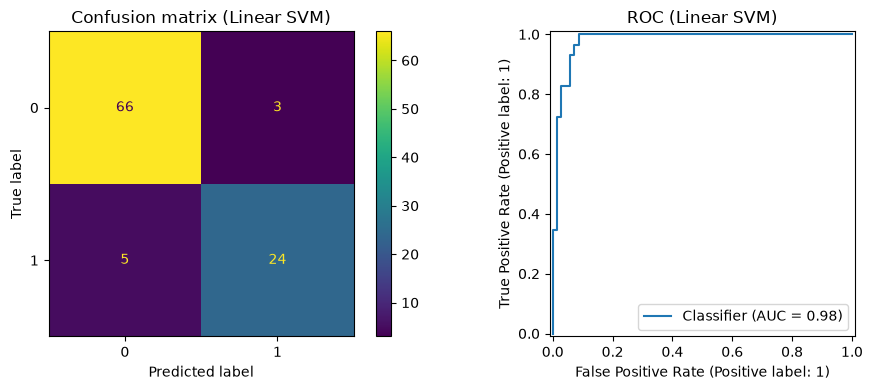

              precision    recall  f1-score   support

           0       0.93      0.96      0.94        69
           1       0.89      0.83      0.86        29

    accuracy                           0.92        98
   macro avg       0.91      0.89      0.90        98
weighted avg       0.92      0.92      0.92        98



Accuracy     0.918367
Precision    0.888889
Recall       0.827586
F1           0.857143
ROC-AUC      0.980010
Name: Linear SVM, dtype: float64

In [22]:

#отдельный пайплайн, чтобы не было утечек данных в кросс валидации из-за трансформера
svm = Pipeline([('transformer', transformer), ('classifier', SVC(kernel='linear'))])


svm_grid = GridSearchCV(
    svm,
    param_grid={
        'classifier__C': np.logspace(-3, 2, 6)
    },
    scoring='f1',
    cv=5
)

svm_grid.fit(X_train, y_train)

svm_best = svm_grid.best_estimator_

print("Подобранные гиперпараметры:")
display(pd.DataFrame(svm_grid.best_params_, index=['Value']))


calculate_metrics(svm_best, 'Linear SVM')

### Учет несбалансированности классов

Для учета несбалансированности классов можно использовать раздельные штрафы для положительного и отрицательного классов. Это реализуется с помощью `class_weight=balanced`, что заставляет модель автоматически перераспределять штрафы обратно пропорционально частотам классов


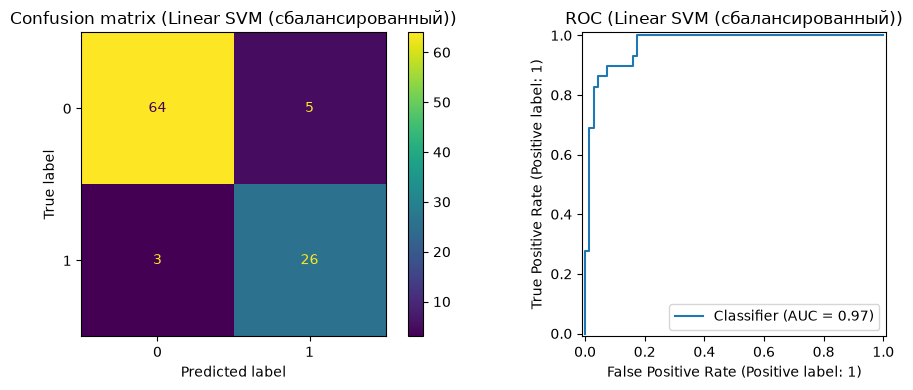

              precision    recall  f1-score   support

           0       0.96      0.93      0.94        69
           1       0.84      0.90      0.87        29

    accuracy                           0.92        98
   macro avg       0.90      0.91      0.90        98
weighted avg       0.92      0.92      0.92        98



Accuracy     0.918367
Precision    0.838710
Recall       0.896552
F1           0.866667
ROC-AUC      0.968516
Name: Linear SVM (сбалансированный), dtype: float64

In [23]:

svm_balanced = GridSearchCV(
    svm,
    param_grid={
        'classifier__C': np.logspace(-3, 2, 6),
        'classifier__class_weight': ['balanced']
    },
    scoring='f1',
    cv=5
)

svm_balanced.fit(X_train, y_train)

calculate_metrics(svm_balanced, 'Linear SVM (сбалансированный)')

### Вывод

Линейный SVM показывает качество, сопоставимое с логистической регрессией. ROC-AUC практически совпадает, а F1 и recall отличаются на пару объектов, так что можно сказать, что разница лежит в пределах шума.

Balanced SVM показывает рост recall до уровня, близкого к логистической регрессии, но за счет precision итоговый F1 изменился незначительно, а ROC-AUC немного снизился. Это говорит о том, что изначальный дисбаланс классов умеренный, а балансировка в данном случае не сильно эффективна


### Сравнение моделей

,Accuracy,Precision,Recall,F1,ROC-AUC
DummyClassifier,0.704082,0.000000,0.000000,0.000000,0.500000
LogisticRegression,0.938776,0.896552,0.896552,0.896552,0.980510
Linear SVM,0.918367,0.888889,0.827586,0.857143,0.980010
Linear SVM balanced,0.918367,0.838710,0.896552,0.866667,0.968516


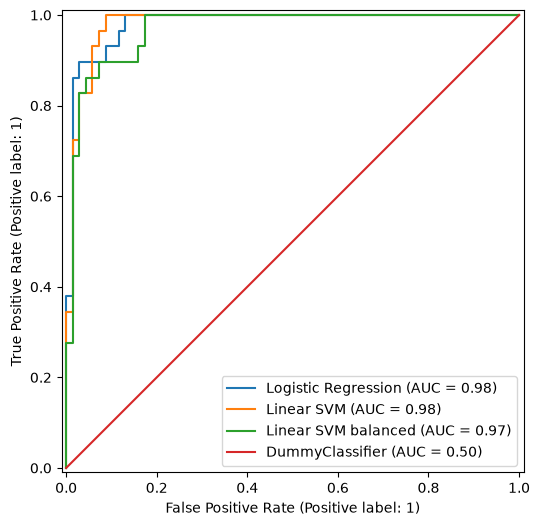

In [24]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

rows = [
    calculate_metrics(dummy, 'DummyClassifier', plots=False),
    calculate_metrics(lr_best, 'LogisticRegression', plots=False),
    calculate_metrics(svm_best, 'Linear SVM', plots=False),
    calculate_metrics(svm_balanced, 'Linear SVM balanced', plots=False),
]
display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
RocCurveDisplay.from_estimator(lr_best, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(svm_best, X_test, y_test, ax=ax, name='Linear SVM')
RocCurveDisplay.from_estimator(svm_balanced, X_test, y_test, ax=ax, name='Linear SVM balanced')
RocCurveDisplay.from_estimator(dummy, X_test, y_test, ax=ax, name='DummyClassifier')

Все три вариации модели значительно превосходят dummy-классификатор по всем параметрам, что говорит о том, что построенные модели способны выполнять задачу классификации удовлетворительно.
 
Лог регрессия и SVM показывают приблизительно одинаковое качество, существенное отличие заключается по большей части в формате выходов моделей